Saving CodeAlpha_Unemployment_Sample_Dataset.csv to CodeAlpha_Unemployment_Sample_Dataset.csv
Dataset Loaded Successfully!

First 5 Rows:
           Region        Date  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh  2019-01-01                              5.2   
1  Andhra Pradesh  2019-06-01                              5.8   
2  Andhra Pradesh  2020-01-01                              5.6   
3  Andhra Pradesh  2020-04-01                             20.5   
4  Andhra Pradesh  2020-10-01                              7.1   

   Estimated Employed  
0            18450000  
1            18120000  
2            18200000  
3            15000000  
4            17600000  

Dataset Shape:
(49, 4)

Column Names:
['Region', 'Date', 'Estimated Unemployment Rate (%)', 'Estimated Employed']

Missing Values:
Region                             0
Date                               0
Estimated Unemployment Rate (%)    0
Estimated Employed                 0
dtype: int64

Cleaned Dataset:
          

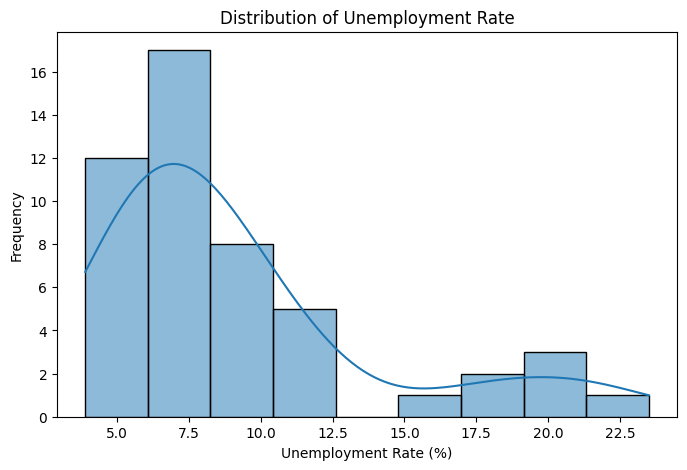

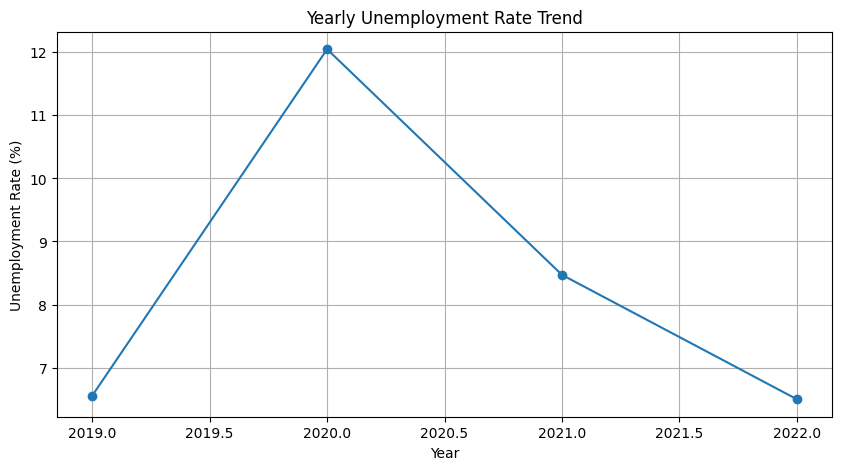


Region-wise Average Unemployment Rate:
Region
Bihar             11.642857
Delhi             10.442857
Uttar Pradesh      9.042857
Kerala             9.014286
Andhra Pradesh     8.071429
Maharashtra        8.014286
Tamil Nadu         8.000000
Name: Estimated Unemployment Rate (%), dtype: float64


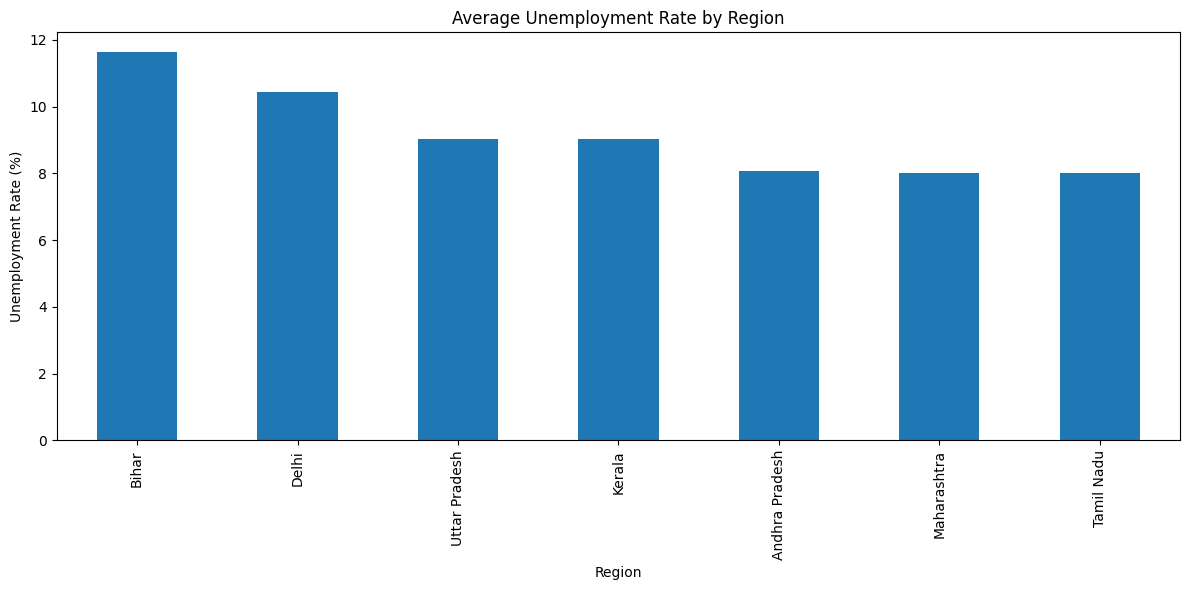


COVID-19 Unemployment Analysis:
Period
After COVID-19     6.500000
Before COVID-19    9.851429
During COVID-19    8.471429
Name: Estimated Unemployment Rate (%), dtype: float64


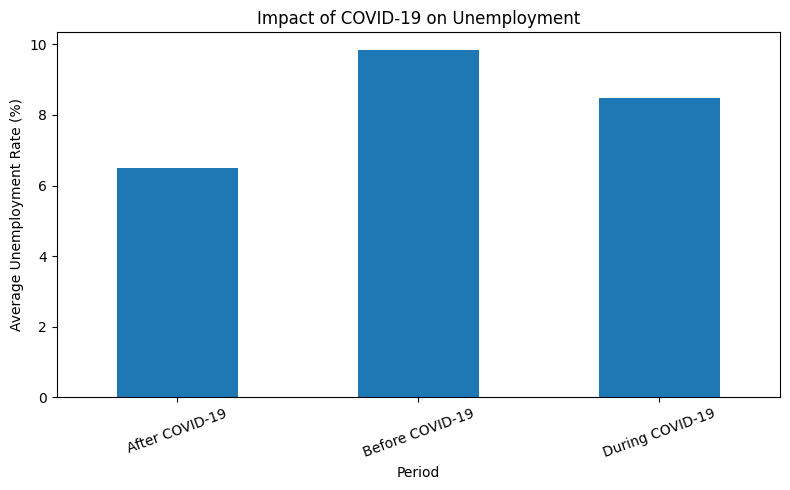


========== FINAL ANALYSIS ==========
Average Unemployment Rate: 9.18 %
Highest Unemployment Rate: 23.5 %
Lowest Unemployment Rate: 3.9 %

Unemployment Analysis Completed Successfully!

Cleaned Dataset Saved Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files



uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset Loaded Successfully!")



print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())



df.columns = df.columns.str.strip()

df = df.drop_duplicates()

print("\nMissing Values:")
print(df.isnull().sum())


rate_col = next(
    (c for c in df.columns if "unemployment rate" in c.lower()),
    None
)

if rate_col is None:
    raise ValueError("Unemployment rate column not found. Check column names.")

df[rate_col] = pd.to_numeric(
    df[rate_col].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

df = df.dropna(subset=[rate_col])


date_col = next(
    (c for c in df.columns if c.lower() in ["date", "month"]),
    None
)

if date_col:
    df[date_col] = pd.to_datetime(
        df[date_col],
        errors="coerce",
        dayfirst=True
    )

print("\nCleaned Dataset:")
print(df.head())



print("\nUnemployment Rate Statistics:")

print(df[rate_col].describe())

average_rate = df[rate_col].mean()
highest_rate = df[rate_col].max()
lowest_rate = df[rate_col].min()

print("\nAverage Unemployment Rate:", round(average_rate, 2), "%")
print("Highest Unemployment Rate:", round(highest_rate, 2), "%")
print("Lowest Unemployment Rate:", round(lowest_rate, 2), "%")



plt.figure(figsize=(8,5))

sns.histplot(df[rate_col], kde=True)

plt.title("Distribution of Unemployment Rate")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")

plt.show()



if date_col and df[date_col].notna().any():

    time_df = df.dropna(subset=[date_col]).copy()

    time_df["Year"] = time_df[date_col].dt.year

    yearly_data = time_df.groupby("Year")[rate_col].mean()

    plt.figure(figsize=(10,5))

    yearly_data.plot(marker="o")

    plt.title("Yearly Unemployment Rate Trend")
    plt.xlabel("Year")
    plt.ylabel("Unemployment Rate (%)")

    plt.grid()
    plt.show()

else:
    print("Date column not available.")



region_col = next(
    (c for c in df.columns
     if c.lower() in ["region", "state", "country"]),
    None
)

if region_col:

    region_data = df.groupby(region_col)[rate_col].mean()

    region_data = region_data.sort_values(ascending=False)

    print("\nRegion-wise Average Unemployment Rate:")
    print(region_data)

    plt.figure(figsize=(12,6))

    region_data.plot(kind="bar")

    plt.title("Average Unemployment Rate by Region")
    plt.xlabel("Region")
    plt.ylabel("Unemployment Rate (%)")

    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


if date_col and df[date_col].notna().any():

    covid_df = df.dropna(subset=[date_col]).copy()

    covid_df["Period"] = np.select(
        [
            covid_df[date_col] < pd.Timestamp("2020-03-01"),

            covid_df[date_col].between(
                pd.Timestamp("2020-03-01"),
                pd.Timestamp("2021-12-31")
            )
        ],
        [
            "Before COVID-19",
            "During COVID-19"
        ],
        default="After COVID-19"
    )

    covid_analysis = covid_df.groupby("Period")[rate_col].mean()

    print("\nCOVID-19 Unemployment Analysis:")
    print(covid_analysis)

    plt.figure(figsize=(8,5))

    covid_analysis.plot(kind="bar")

    plt.title("Impact of COVID-19 on Unemployment")
    plt.xlabel("Period")
    plt.ylabel("Average Unemployment Rate (%)")

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


print("\n========== FINAL ANALYSIS ==========")

print("Average Unemployment Rate:",
      round(average_rate, 2), "%")

print("Highest Unemployment Rate:",
      round(highest_rate, 2), "%")

print("Lowest Unemployment Rate:",
      round(lowest_rate, 2), "%")

print("\nUnemployment Analysis Completed Successfully!")


df.to_csv("unemployment_cleaned.csv", index=False)

print("\nCleaned Dataset Saved Successfully!")

files.download("unemployment_cleaned.csv")
